# Ramen on EuroSAT: evaluation and failure analysis

Runs **Ramen** and a **NoAdapt** baseline (zero-shot CLIP ViT-B/16) on exactly the same test stream. EuroSAT RGB: 27,000 64×64 Sentinel-2 images, 10 land-cover classes, **one domain**. The shift here is natural photos → satellite images, not a mix of domains, so `mixed` is just one shuffled stream of 27k images.

Setup, fixed before looking at results:
- **Prompts**: `"a centered satellite photo of {}."` with CoOp's class names (`Annual Crop Land`, `Highway or Road`, ...), the standard EuroSAT setup in the CLIP TTA literature. The repo's default 7-template ensemble (`"itap of a {}."`, `"a origami {}."`, ...) is run as a sensitivity check in section 8.
- **Ramen config**: `cfg/EuroSAT/Ramen.yaml` = CIFAR-10-C's (max_capacity 7500, topk 50, beta 5, SignSGD lr 0.01), the other 10-class setup. Not tuned on EuroSAT; two other configs are in section 8.
- The stream (27k) is shorter than 65,520, so the fp16 priority overflow bug never triggers.
- Images: all 27,000 (no official test split; CoOp's 8,100-image test split is a subset of these).

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import numpy as np
import pandas as pd
import torch
from ramen_analysis import EuroSATExperiment
from marginal_correction import corrected_probs

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = EuroSATExperiment(
    model='clip_vitbase16',
    tta_mode='mixed',
    batch_size=100,
    n_per_domain=None,     # None = all 27,000 images
    seed=0,
    num_workers=16,
).load()

EuroSAT: 1 domains x 27000 images, 10 classes, model=clip_vitbase16, mode=mixed


In [3]:
acc = exp.evaluate(capture_probs=True, capture_features=True)   # pass use_cache=False to force a re-run
acc

39936


NoAdapt:   0%|          | 0/270 [00:00<?, ?it/s]

NoAdapt:   0%|          | 1/270 [00:02<09:58,  2.22s/it]

NoAdapt:   1%|          | 2/270 [00:02<04:29,  1.00s/it]

NoAdapt:   1%|          | 3/270 [00:02<03:34,  1.25it/s]

...

Ramen:  99%|█████████▉| 268/270 [01:43<00:00,  2.63it/s]

Ramen: 100%|█████████▉| 269/270 [01:43<00:00,  2.63it/s]

Ramen: 100%|██████████| 270/270 [01:44<00:00,  2.63it/s]

Ramen: 100%|██████████| 270/270 [01:44<00:00,  2.59it/s]

,NoAdapt,Ramen,delta
satellite,48.07,62.63,14.56
average,48.07,62.63,14.56


In [4]:
exp.summary_metrics().drop(['noise', 'other'])

avg               62.629630
fixed %           18.544444
broken %           3.981481
TV(pred, true)     0.247667
ECE                9.284681
acc satellite     62.629630
dtype: float64

## 1. Per-class accuracy
EuroSAT has one domain, so the per-domain plots of the other notebooks reduce to a single bar; per class is the useful breakdown.

In [5]:
r, b = exp.results['Ramen'], exp.results['NoAdapt']
per_class = pd.DataFrame({'NoAdapt': b.groupby('label')['correct'].mean() * 100,
                          'Ramen': r.groupby('label')['correct'].mean() * 100,
                          'NoAdapt pred share %': np.bincount(b.pred, minlength=10) / len(b) * 100,
                          'Ramen pred share %': np.bincount(r.pred, minlength=10) / len(r) * 100,
                          'true share %': r.groupby('label').size() / len(r) * 100})
per_class['delta'] = per_class['Ramen'] - per_class['NoAdapt']
per_class.index = [exp.classes[i] for i in per_class.index]
per_class.sort_values('delta').round(2)

,NoAdapt,Ramen,NoAdapt pred share %,Ramen pred share %,true share %,delta
Pasture Land,53.60,46.45,9.09,5.99,7.41,-7.15
Herbaceous Vegetation Land,6.67,0.30,1.97,0.08,11.11,-6.37
Residential Buildings,95.73,99.33,14.43,14.24,11.11,3.60
Permanent Crop Land,14.36,19.80,2.21,4.09,9.26,5.44
Industrial Buildings,81.52,88.68,10.80,9.81,9.26,7.16
River,47.00,57.80,4.85,6.26,9.26,10.80
Highway or Road,71.44,91.92,26.41,21.01,9.26,20.48
Annual Crop Land,67.80,91.20,17.19,17.61,11.11,23.40
Forest,34.97,72.30,10.57,13.95,11.11,37.33
Sea or Lake,13.10,54.40,2.49,6.97,11.11,41.30


## 2. Prediction bias / class collapse
Predicted share of each class minus its true share. Large positive bars are "attractor" classes.

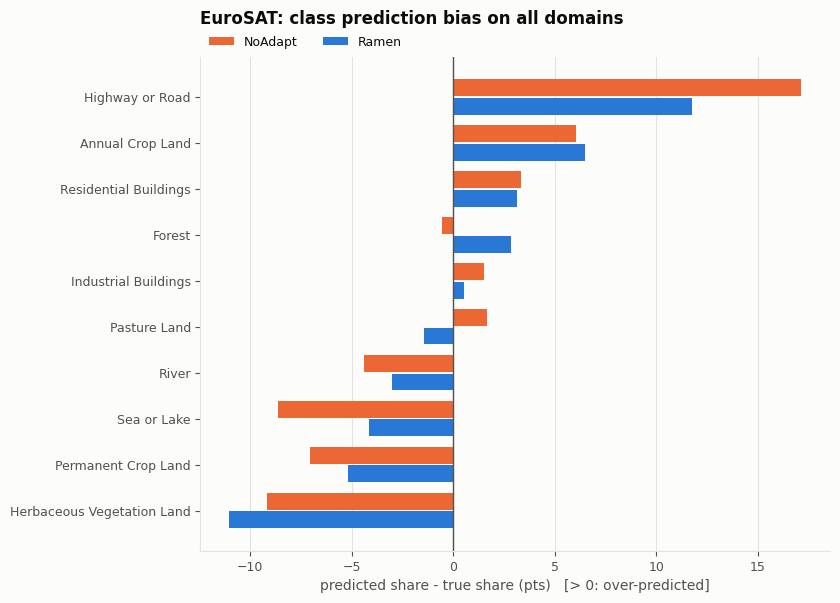

In [6]:
exp.plot_prediction_bias();

## 3. What gets confused with what
Rows = true class, columns = predicted class, % of the true class.

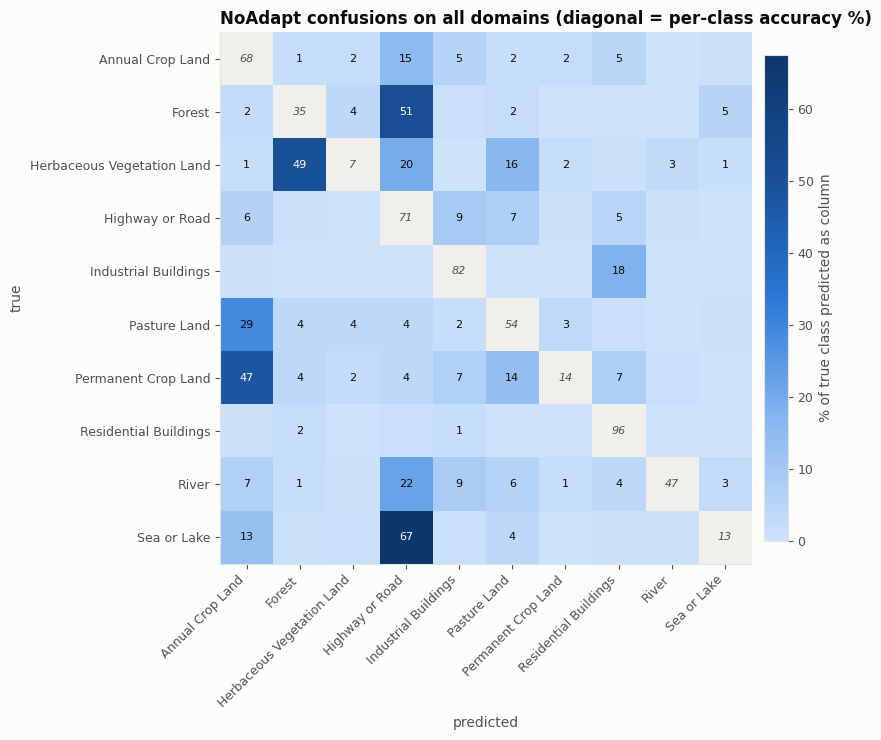

In [7]:
exp.plot_confusion(algo='NoAdapt');

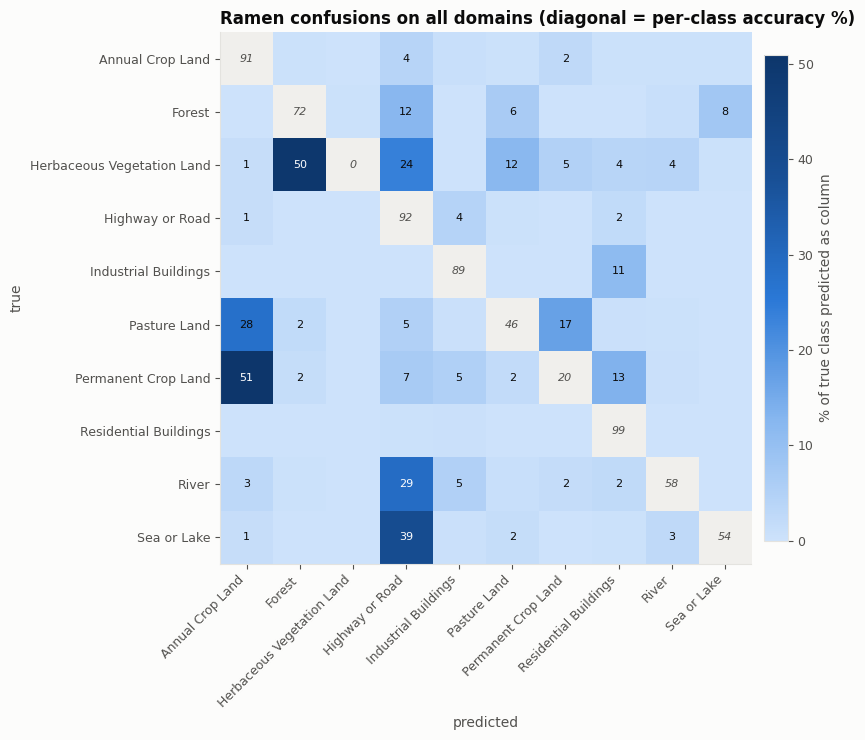

In [8]:
exp.plot_confusion(algo='Ramen');

In [9]:
exp.error_granularity()   # vegetation / built / water

,NoAdapt % errors within superclass,Ramen % errors within superclass
satellite,42.1,51.3
average,42.1,51.3


## 4. Does Ramen degrade (or warm up) over the stream?
Top: rolling accuracy. Bottom: rolling Ramen − NoAdapt gap. The cache starts empty, so early samples get little help.

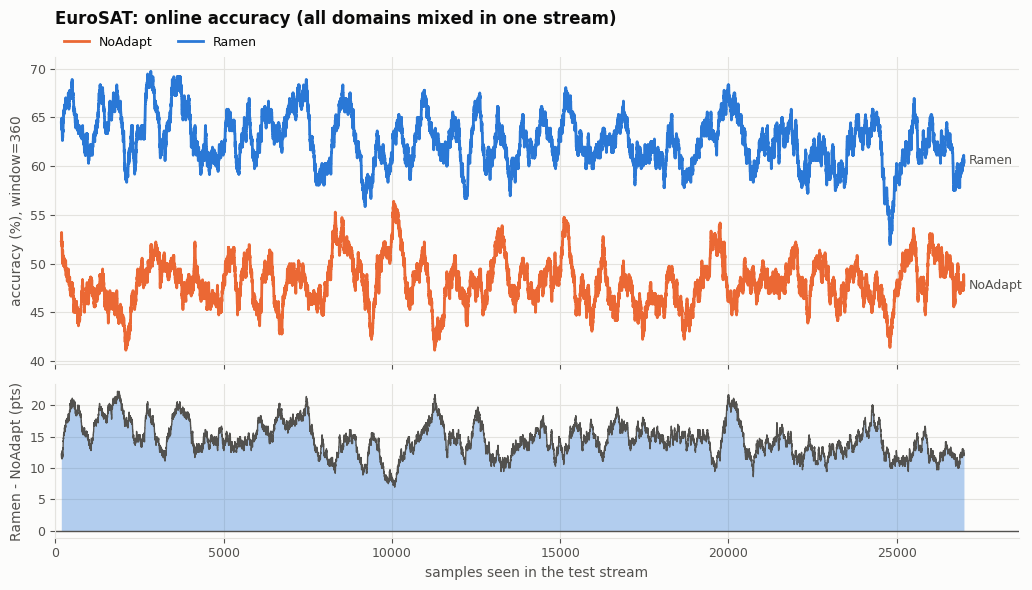

In [10]:
exp.plot_online_accuracy();

## 5. Calibration

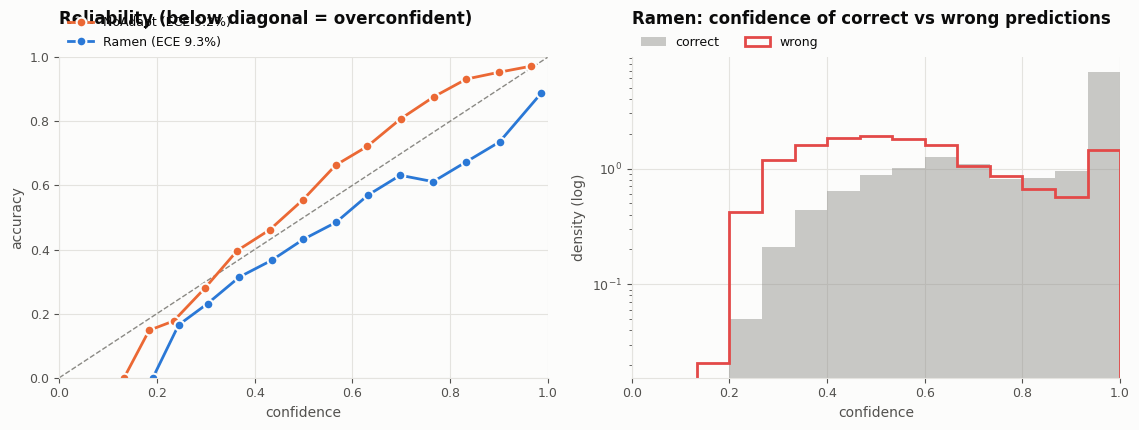

In [11]:
exp.plot_calibration();

## 6. Look at the failures
`kind='broken'`: Ramen broke a correct zero-shot prediction; `'fixed'`: the reverse.

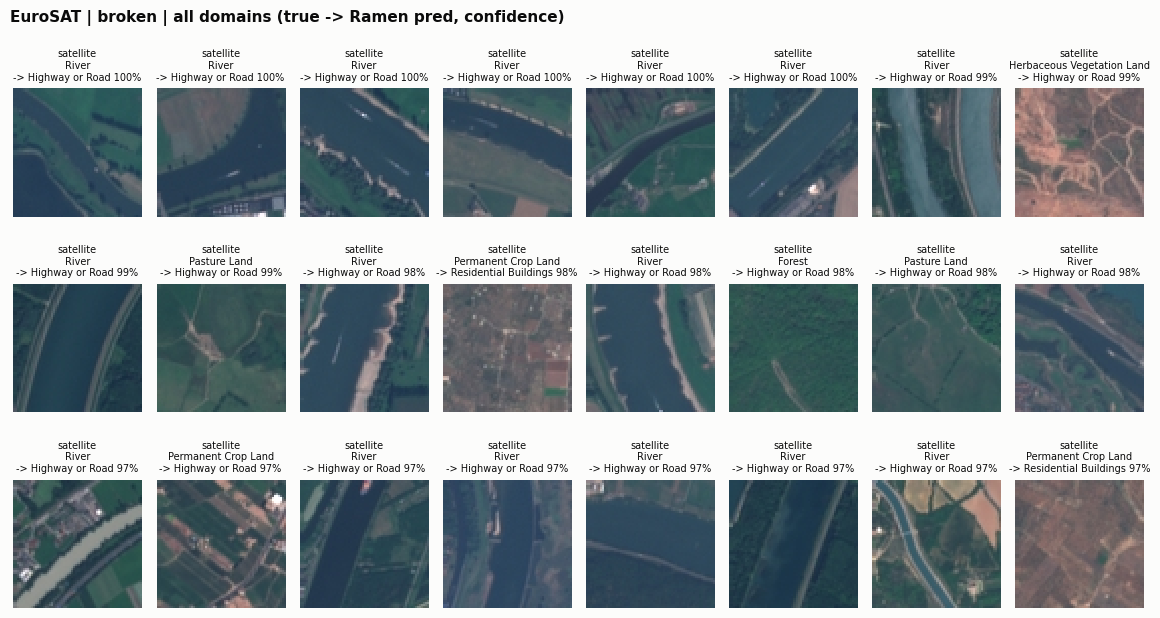

In [12]:
exp.show_failures(kind='broken', n=24);

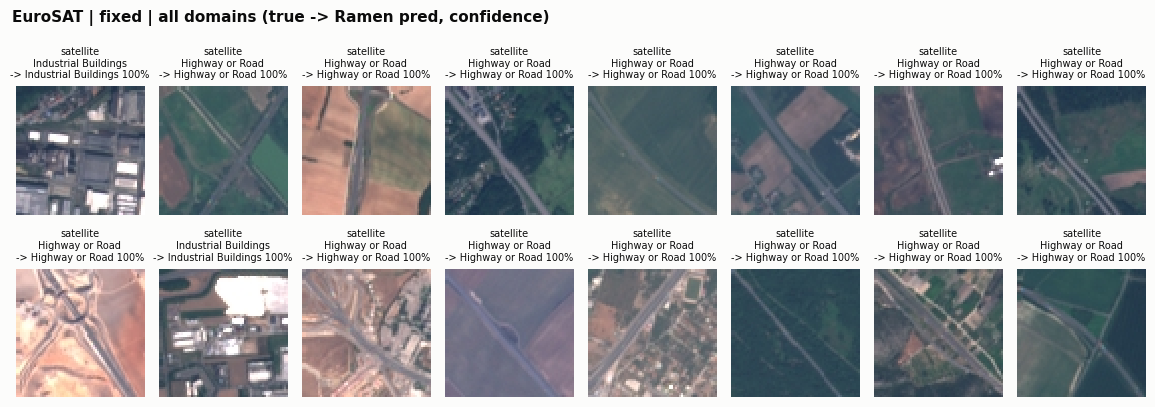

In [13]:
exp.show_failures(kind='fixed', n=16);

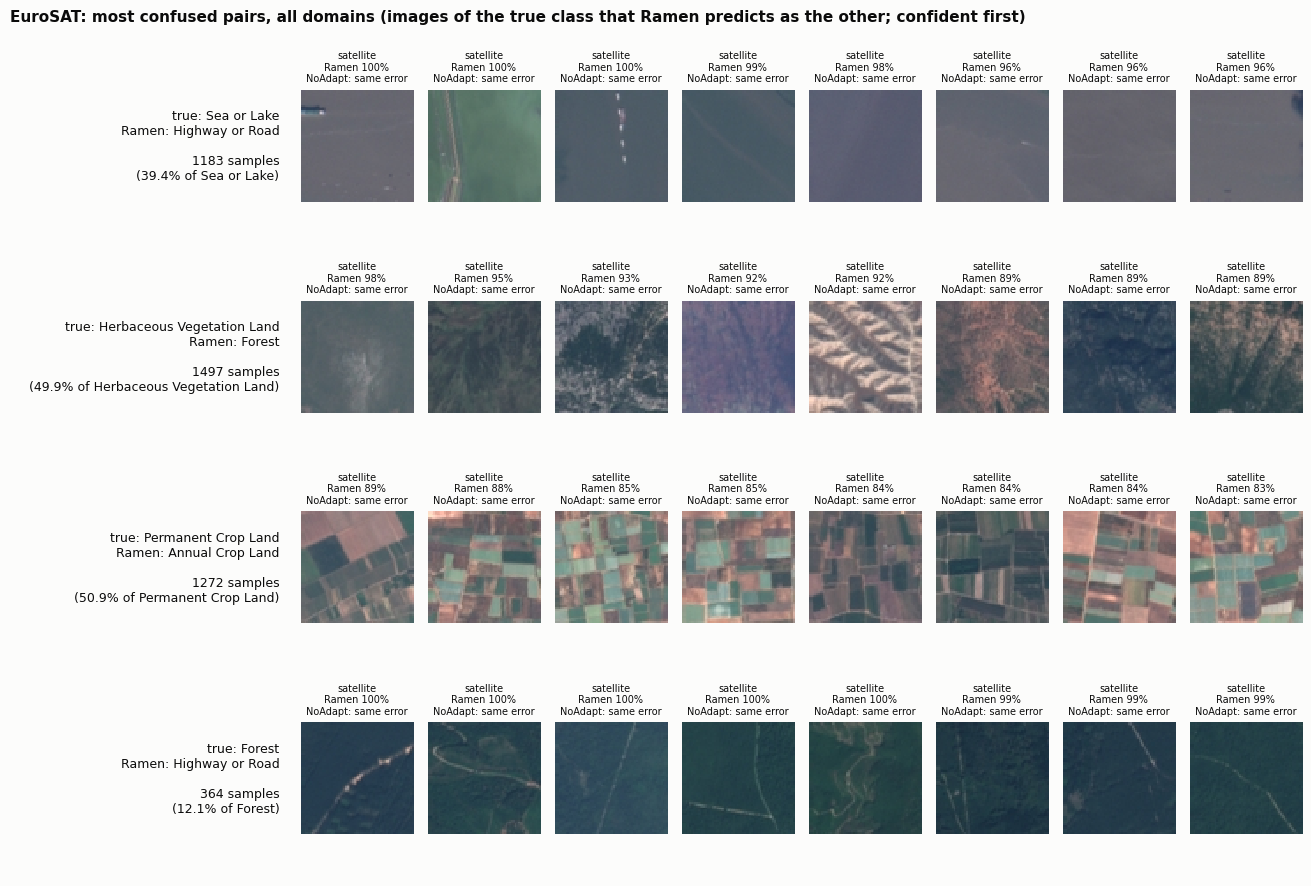

In [14]:
exp.show_confused_pairs(top_k=4, n=8);

## 7. Would "keep zero-shot when it is confident" help?
Post-hoc gate, exact because the memory doesn't change. `oracle` is the ceiling for any per-sample choice between zero-shot and Ramen.

In [15]:
gate = exp.gate_sweep()
print(f"Ramen: {gate.attrs['Ramen']:.2f}   oracle (either right): {gate.attrs['oracle']:.2f}")
gate

Ramen: 62.63   oracle (either right): 66.61


,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,
0.50,35.50,81.80,83.95,61.87,85,291
0.60,26.38,88.01,88.64,62.46,36,81
0.70,19.87,92.53,92.53,62.63,15,15
0.80,13.91,95.26,95.26,62.63,2,2
0.90,6.95,96.54,96.48,62.63,1,0
0.95,3.39,97.92,97.81,62.63,1,0
0.99,0.48,99.23,99.23,62.63,0,0


## 8. Sensitivity: prompts, cache config, backbone, seed
Every row is a separate full run (seed 0 unless stated), all reported, none picked.

In [16]:
# Prompts: the repo's default 7-template ensemble instead of the satellite prompt
exp.run('NoAdapt', name='NoAdapt_ens7', cfg={'templates': None})
exp.run('Ramen', name='Ramen_ens7', cfg={'templates': None})
# Cache config: DomainNet's and ImageNetC5K's instead of CIFAR-10-C's
exp.run('Ramen', name='Ramen_cap300_k10', cfg={'max_capacity': 300, 'topk': 10})
exp.run('Ramen', name='Ramen_cap75_k1_b0', cfg={'max_capacity': 75, 'topk': 1, 'beta': 0.0})

def acc_of(e, name):
    return e.results[name]['correct'].mean() * 100

rows = [('ViT-B/16', 'satellite', 'C10 (7500/50/b5)', acc_of(exp, 'NoAdapt'), acc_of(exp, 'Ramen')),
        ('ViT-B/16', 'ensemble-7', 'C10 (7500/50/b5)', acc_of(exp, 'NoAdapt_ens7'), acc_of(exp, 'Ramen_ens7')),
        ('ViT-B/16', 'satellite', 'DomainNet (300/10/b5)', acc_of(exp, 'NoAdapt'), acc_of(exp, 'Ramen_cap300_k10')),
        ('ViT-B/16', 'satellite', 'ImageNetC (75/1/b0)', acc_of(exp, 'NoAdapt'), acc_of(exp, 'Ramen_cap75_k1_b0'))]

39936


NoAdapt_ens7:   0%|          | 0/270 [00:00<?, ?it/s]

NoAdapt_ens7:   0%|          | 1/270 [00:01<08:12,  1.83s/it]

NoAdapt_ens7:   1%|          | 2/270 [00:01<03:38,  1.23it/s]

NoAdapt_ens7:   1%|▏         | 4/270 [00:02<01:36,  2.76it/s]

...

Ramen_cap75_k1_b0:  99%|█████████▉| 267/270 [01:38<00:01,  2.78it/s]

Ramen_cap75_k1_b0:  99%|█████████▉| 268/270 [01:38<00:00,  2.78it/s]

Ramen_cap75_k1_b0: 100%|█████████▉| 269/270 [01:39<00:00,  2.78it/s]

Ramen_cap75_k1_b0: 100%|██████████| 270/270 [01:39<00:00,  2.78it/s]

Ramen_cap75_k1_b0: 100%|██████████| 270/270 [01:39<00:00,  2.71it/s]

In [17]:
# Backbone: ViT-B/32 (the CIFAR-10-C / DomainNet backbone)
exp32 = EuroSATExperiment(model='clip_vitbase32', seed=0, num_workers=16).load()
exp32.evaluate()
exp32.run('NoAdapt', name='NoAdapt_ens7', cfg={'templates': None})
exp32.run('Ramen', name='Ramen_ens7', cfg={'templates': None})
rows += [('ViT-B/32', 'satellite', 'C10 (7500/50/b5)', acc_of(exp32, 'NoAdapt'), acc_of(exp32, 'Ramen')),
         ('ViT-B/32', 'ensemble-7', 'C10 (7500/50/b5)', acc_of(exp32, 'NoAdapt_ens7'), acc_of(exp32, 'Ramen_ens7'))]
del exp32; torch.cuda.empty_cache()

sens = pd.DataFrame(rows, columns=['model', 'prompt', 'Ramen config', 'NoAdapt', 'Ramen'])
sens['delta'] = sens['Ramen'] - sens['NoAdapt']
sens.round(2)

EuroSAT: 1 domains x 27000 images, 10 classes, model=clip_vitbase32, mode=mixed
39936


NoAdapt:   0%|          | 0/270 [00:00<?, ?it/s]

NoAdapt:   0%|          | 1/270 [00:02<11:30,  2.57s/it]

NoAdapt:   1%|▏         | 4/270 [00:02<02:17,  1.93it/s]

NoAdapt:   3%|▎         | 7/270 [00:02<01:08,  3.86it/s]

...

Ramen_ens7:  99%|█████████▉| 268/270 [00:40<00:00,  6.85it/s]

Ramen_ens7: 100%|█████████▉| 269/270 [00:40<00:00,  6.86it/s]

Ramen_ens7: 100%|██████████| 270/270 [00:40<00:00,  6.87it/s]

Ramen_ens7: 100%|██████████| 270/270 [00:40<00:00,  6.62it/s]

,model,prompt,Ramen config,NoAdapt,Ramen,delta
0,ViT-B/16,satellite,C10 (7500/50/b5),48.07,62.63,14.56
1,ViT-B/16,ensemble-7,C10 (7500/50/b5),50.63,58.54,7.90
2,ViT-B/16,satellite,DomainNet (300/10/b5),48.07,60.74,12.67
3,ViT-B/16,satellite,ImageNetC (75/1/b0),48.07,56.84,8.77
4,ViT-B/32,satellite,C10 (7500/50/b5),45.46,57.97,12.51
5,ViT-B/32,ensemble-7,C10 (7500/50/b5),42.87,46.57,3.70


In [18]:
# Seeds 0-4 (stream order) for the main setup. NoAdapt is per-sample, so it doesn't depend on the order.
seed_exps = {0: exp}
for s in range(1, 5):
    seed_exps[s] = EuroSATExperiment(model='clip_vitbase16', seed=s, num_workers=16).load()
    seed_exps[s].evaluate(capture_probs=True, capture_features=True)
seeds = pd.DataFrame({s: {'NoAdapt': acc_of(e, 'NoAdapt'), 'Ramen': acc_of(e, 'Ramen')} for s, e in seed_exps.items()}).T
seeds['delta'] = seeds['Ramen'] - seeds['NoAdapt']
print('delta mean ± std over seeds: %.2f ± %.2f' % (seeds['delta'].mean(), seeds['delta'].std()))
seeds.round(2)

EuroSAT: 1 domains x 27000 images, 10 classes, model=clip_vitbase16, mode=mixed
39936


NoAdapt:   0%|          | 0/270 [00:00<?, ?it/s]

NoAdapt:   0%|          | 1/270 [00:02<09:46,  2.18s/it]

NoAdapt:   1%|          | 2/270 [00:02<04:21,  1.03it/s]

NoAdapt:   1%|          | 3/270 [00:02<02:46,  1.60it/s]

...

Ramen: 100%|█████████▉| 269/270 [01:44<00:00,  2.63it/s]

Ramen: 100%|██████████| 270/270 [01:45<00:00,  2.63it/s]

Ramen: 100%|██████████| 270/270 [01:45<00:00,  2.56it/s]

delta mean ± std over seeds: 14.36 ± 0.30


,NoAdapt,Ramen,delta
0,48.07,62.63,14.56
1,48.07,62.36,14.29
2,48.07,62.52,14.45
3,48.07,62.68,14.61
4,48.07,61.93,13.86


## 9. Held-out check of the CIFAR fixes
Both are offline and exact, because Ramen's outputs never feed back into its cache. Settings are fixed in advance from the CIFAR runs:
- **prior correction**: `logit − 2·log(EMA marginal / uniform)`, momentum 0.99, soft. EuroSAT's classes are nearly balanced (7.4–11.1%), so the uniform target is roughly right here, unlike ImageNet-C and DomainNet.
- **kNN smoothing**: mix Ramen's output 50/50 with the average output of the 10 nearest earlier images (zero-shot features, temperature 0.01, earlier batches only).

In [19]:
def knn_smooth(P, Z, batch_start, K=10, temp=0.01):
    """Same as quick_checks/knn_seeds.smooth: similarity-weighted mean of the K nearest earlier-batch outputs."""
    N, Q = len(P), P.clone()
    for s in range(100, N, 1000):
        e = min(s + 1000, N)
        sim = Z[s:e] @ Z[:e].T
        bs = torch.tensor(batch_start[s:e], device=P.device)
        sim[torch.arange(e, device=P.device)[None, :] >= bs[:, None]] = -float('inf')
        v, idx = sim.topk(min(K, s), dim=1)
        Q[s:e] = (torch.softmax(v / temp, dim=1)[..., None] * P[idx]).sum(1)
    return Q


def with_prior_correction(e, p, lam=2.0, m=0.99):
    """marginal_correction.corrected_probs on arbitrary softmax rows p (row i <-> e.results['Ramen'].iloc[i])."""
    e.probs['_tmp'], e.results['_tmp'] = p, e.results['Ramen']
    q = corrected_probs(e, '_tmp', lam=lam, momentum=m)
    del e.probs['_tmp'], e.results['_tmp']
    return q


rows = []
for s, e in seed_exps.items():
    r, z = e.results['Ramen'], e.results['NoAdapt']
    assert (r.position.values == np.arange(len(r))).all()
    y = r.label.values
    acc = lambda p: (p.argmax(1) == y).mean() * 100
    P = torch.tensor(e.probs['Ramen'], device='cuda').float()
    # zero-shot features as keys, in Ramen's stream order (NoAdapt saw the same order)
    assert (z.sample_idx.values == r.sample_idx.values).all()
    Z = torch.nn.functional.normalize(torch.tensor(e.features['NoAdapt'], device='cuda').float(), dim=1)
    S = (0.5 * P + 0.5 * knn_smooth(P, Z, (np.arange(len(r)) // 100) * 100)).cpu().numpy()
    base = acc(e.probs['Ramen'])
    rows.append({'seed': s, 'NoAdapt': acc(e.probs['NoAdapt']), 'Ramen': base,
                 'prior corr.': acc(corrected_probs(e, 'Ramen', lam=2.0, momentum=0.99)) - base,
                 'kNN smooth': acc(S) - base,
                 'smooth + prior corr.': acc(with_prior_correction(e, S)) - base})
fixes = pd.DataFrame(rows).set_index('seed')
print('gain over Ramen (pts), mean ± std:',
      ', '.join(f'{c} {fixes[c].mean():+.2f} ± {fixes[c].std():.2f}' for c in fixes.columns[2:]))
fixes.round(2)

gain over Ramen (pts), mean ± std: prior corr. +2.79 ± 0.28, kNN smooth +2.06 ± 0.11, smooth + prior corr. +7.02 ± 0.28


,NoAdapt,Ramen,prior corr.,kNN smooth,smooth + prior corr.
seed,,,,,
0,48.07,62.63,2.49,2.03,6.77
1,48.07,62.36,2.55,1.97,6.93
2,48.07,62.52,3.00,2.15,7.45
3,48.07,62.68,3.14,2.20,7.14
4,48.07,61.93,2.78,1.94,6.80
